# CONUS at 2 Gt yr⁻¹

Plot the results from the 2Gt/yr case of [Beerling et al. (2025)](https://doi.org/10.1038/s41586-024-08429-2).

1. **Soil CO₂**.
2. **pH**.
3. **Validation**: we reproduce the published national (gross) CDR curve.
4. **CDR under E1 and E2**: optimizing for alkalinity export vs. for pH. CDR here includes carbonate
   precipitation.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os
from pathlib import Path
import numpy as np, xarray as xr, matplotlib as mpl, matplotlib.pyplot as plt
from beerling_analysis import io

mpl.rcParams.update({"font.size": 10, "figure.dpi": 120, "axes.grid": False})
OI = dict(blue="#0072B2", vermillion="#D55E00", green="#009E73",
          orange="#E69F00", purple="#CC79A7", sky="#56B4E9", grey="0.45")

TAG      = "e0-conus-2gt"
ROOT     = "s3://carbonplan-carbon-removal/ew-workflows-data/beerling-2025-model-extension"
POSTPROC = os.environ.get("BEERLING_POSTPROC", f"{ROOT}/postproc/{TAG}")
FIGDIR   = Path("../figures") if Path("../figures").is_dir() else Path("figures")
FIGDIR.mkdir(exist_ok=True)

pt   = xr.open_zarr(f"{POSTPROC}/point.zarr").load()
SCEN = int(str(pt.attrs["scenario"]).lstrip("S"))
YRS  = pt.time.values

# deployed point-years only (before start_year the column is control soil)
ACT  = pt.time >= pt.start_year
AREA = (pt.area_ha * xr.ones_like(pt.time, dtype=float)).where(ACT)

def flat(v, positive=False):
    """Active point-years of `v`, paired with their hectares. NaNs dropped."""
    x, w = pt[v].where(ACT).values.ravel(), AREA.values.ravel()
    m = np.isfinite(x) & np.isfinite(w)
    if positive:
        m &= x > 0
    return x[m], w[m]

def wq(x, w, q):
    """Weighted quantile, linear interpolation on the midpoint CDF."""
    o = np.argsort(x); x, w = x[o], w[o]
    return np.interp(q, (np.cumsum(w) - 0.5 * w) / w.sum(), x)

def wfrac(x, w, thr):
    return float(w[x > thr].sum() / w.sum())

def national(v):
    """Per-point cumulative t CO2 -> national annual Gt CO2/yr (difference, then sum)."""
    cum = pt[v].fillna(0.0)
    return ((cum - cum.shift(time=1, fill_value=0.0)).sum("point") / 1e9).values

print(f"{POSTPROC}/point.zarr")
print(f"  S{SCEN}  {pt.sizes['point']:,} points / {int(pt.cluster.to_series().nunique())} "
      f"clusters  {float(pt.area_ha.sum())/1e6:.2f} M ha  {int(YRS[0])}-{int(YRS[-1])}")
print(f"  {int(ACT.sum()):,} deployed point-years of {pt.sizes['point'] * pt.sizes['time']:,}")

s3://carbonplan-carbon-removal/ew-workflows-data/beerling-2025-model-extension/postproc/e0-conus-2gt/point.zarr
  S2  3,904 points / 338 clusters  49.18 M ha  2020-2070
  97,530 deployed point-years of 199,104


## 1. Modeled vs. equilibrium-required soil CO2

**a** Both distributions. **b** Required ÷ modeled per point-year (can't be computed from the annual
postprocessed data, because of Jensen's inequality and carbonate nonlinearity).

modelled soil pCO2   median     1,851 ppm   (p5 1,160, p95 2,144)
required  soil pCO2  median   142,922 ppm   (p5 40,211, p95 255,997)  = 14% of an atmosphere of pure CO2
multiple             median        64 x     (p5 27, p95 108)
0.50% of deployed cropland-years need a NEGATIVE pCO2 -- unclosable at any value


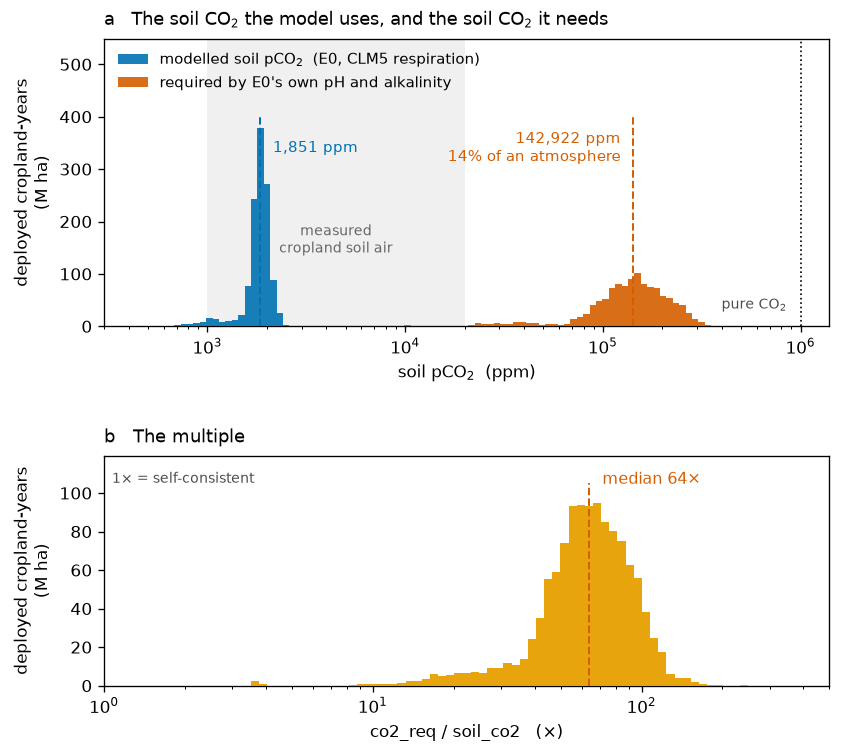

In [2]:
co2, wco2 = flat("soil_co2", positive=True)
req, wreq = flat("co2_req",  positive=True)
rat, wrat = flat("co2_req_ratio", positive=True)
allreq, wallreq = flat("co2_req")

m_co2, m_req, m_rat = wq(co2, wco2, .5), wq(req, wreq, .5), wq(rat, wrat, .5)
neg = float(wallreq[allreq <= 0].sum() / wallreq.sum())

print(f"modelled soil pCO2   median {m_co2:9,.0f} ppm   "
      f"(p5 {wq(co2, wco2, .05):,.0f}, p95 {wq(co2, wco2, .95):,.0f})")
print(f"required  soil pCO2  median {m_req:9,.0f} ppm   "
      f"(p5 {wq(req, wreq, .05):,.0f}, p95 {wq(req, wreq, .95):,.0f})"
      f"  = {m_req/1e6:.0%} of an atmosphere of pure CO2")
print(f"multiple             median {m_rat:9,.0f} x     "
      f"(p5 {wq(rat, wrat, .05):.0f}, p95 {wq(rat, wrat, .95):.0f})")
print(f"{neg:.2%} of deployed cropland-years need a NEGATIVE pCO2 -- unclosable at any value")

fig, axes = plt.subplots(2, 1, figsize=(7.8, 7.0),
                         gridspec_kw=dict(hspace=.50, height_ratios=[1.25, 1]))

# a
ax = axes[0]
bins = np.logspace(np.log10(3e2), 6, 110)
ax.axvspan(1e3, 2e4, color=OI["grey"], alpha=.10, lw=0, zorder=0)
ax.hist(co2, bins=bins, weights=wco2 / 1e6, color=OI["blue"], alpha=.9, zorder=3,
        label="modelled soil pCO$_2$  (E0, CLM5 respiration)")
ax.hist(req, bins=bins, weights=wreq / 1e6, color=OI["vermillion"], alpha=.9, zorder=3,
        label="required by E0's own pH and alkalinity")
ax.set_xscale("log"); ax.set_xlim(3e2, 1.4e6)
top = ax.get_ylim()[1] * 1.38; ax.set_ylim(0, top)
ax.vlines(m_co2, 0, top * .74, color=OI["blue"],       ls="--", lw=1.2, zorder=4)
ax.vlines(m_req, 0, top * .74, color=OI["vermillion"], ls="--", lw=1.2, zorder=4)
ax.axvline(1e6, color="k", lw=1.0, ls=":", zorder=2)
ax.text(m_co2 * 1.16, top * .62, f"{m_co2:,.0f} ppm", color=OI["blue"],
        fontsize=9, ha="left", va="center")
ax.text(m_req * .86, top * .62, f"{m_req:,.0f} ppm\n{m_req/1e6:.0%} of an atmosphere",
        color=OI["vermillion"], fontsize=9, ha="right", va="center")
ax.text(np.sqrt(1e3 * 2e4), top * .30, "measured\ncropland soil air",
        fontsize=8.5, color="0.4", ha="center", va="center")
ax.text(8.5e5, top * .06, "pure CO$_2$", fontsize=8.5, color="0.3", ha="right")
ax.set_xlabel("soil pCO$_2$  (ppm)")
ax.set_ylabel("deployed cropland-years\n(M ha)")
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.set_title("a   The soil CO$_2$ the model uses, and the soil CO$_2$ it needs",
             loc="left", fontsize=10.5, pad=8)

# b
ax = axes[1]
ax.hist(rat, bins=np.logspace(0, np.log10(500), 90), weights=wrat / 1e6,
        color=OI["orange"], alpha=.95, zorder=3)
ax.set_xscale("log"); ax.set_xlim(1, 500)
top = ax.get_ylim()[1] * 1.20; ax.set_ylim(0, top)
ax.axvline(1, color="k", lw=1.0, ls=":")
ax.vlines(m_rat, 0, top * .88, color=OI["vermillion"], ls="--", lw=1.2, zorder=4)
ax.text(m_rat * 1.12, top * .93, f"median {m_rat:.0f}×", color=OI["vermillion"],
        fontsize=9.5, va="top", ha="left")
ax.text(1.07, top * .93, "1× = self-consistent", fontsize=8.5, color="0.3",
        ha="left", va="top")
ax.set_xlabel("co2_req / soil_co2   (×)")
ax.set_ylabel("deployed cropland-years\n(M ha)")
ax.set_title("b   The multiple", loc="left", fontsize=10.5, pad=8)

fig.savefig(FIGDIR / "05_fig1_soil_co2.png", bbox_inches="tight", dpi=200)
plt.show()

## 2. Porewater pH with a closed carbonate system

The pH needed to carry the modeled alkalinity at the modeled soil CO2 (E1).

column-mean porewater pH, area-weighted median over deployed cropland-years
  control (no feedstock)  6.08
  E0  modelled            7.19   (pH_col, the published reduction: 7.19)
  E1  carbonate-consistent  8.83   (+1.65 vs E0, +2.76 vs control)
above pH 7.5:  E0 11.1%   E1 99.6%


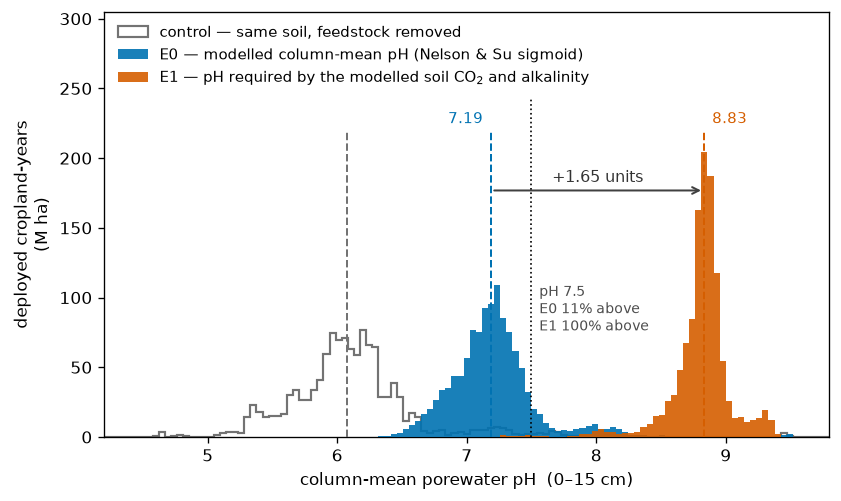

In [3]:
ph0, w0 = flat("pH_diag")      # E0's own pH, on pH_e1's 100/yr grid
ph1, w1 = flat("pH_e1")        # what the carbonate system puts that state at
phc, wc = flat("pH_ctrl")      # same soil, feedstock removed
phm, wm = flat("pH_col")       # the monthly reduction, validated vs published

m0, m1, mc, mm = (wq(ph0, w0, .5), wq(ph1, w1, .5), wq(phc, wc, .5), wq(phm, wm, .5))
f0, f1 = wfrac(ph0, w0, 7.5), wfrac(ph1, w1, 7.5)

print(f"column-mean porewater pH, area-weighted median over deployed cropland-years")
print(f"  control (no feedstock)  {mc:.2f}")
print(f"  E0  modelled            {m0:.2f}   (pH_col, the published reduction: {mm:.2f})")
print(f"  E1  carbonate-consistent{m1:6.2f}   ({m1 - m0:+.2f} vs E0, {m1 - mc:+.2f} vs control)")
print(f"above pH 7.5:  E0 {f0:.1%}   E1 {f1:.1%}")

fig, ax = plt.subplots(figsize=(7.8, 4.6))
bins = np.linspace(4.2, 9.8, 120)
ax.hist(phc, bins=bins, weights=wc / 1e6, histtype="step", lw=1.3, color=OI["grey"],
        zorder=2, label="control — same soil, feedstock removed")
ax.hist(ph0, bins=bins, weights=w0 / 1e6, color=OI["blue"], alpha=.9, zorder=3,
        label="E0 — modelled column-mean pH (Nelson & Su sigmoid)")
ax.hist(ph1, bins=bins, weights=w1 / 1e6, color=OI["vermillion"], alpha=.9, zorder=3,
        label="E1 — pH required by the modelled soil CO$_2$ and alkalinity")

top = ax.get_ylim()[1] * 1.42; ax.set_ylim(0, top); ax.set_xlim(4.2, 9.8)
ax.vlines(7.5, 0, top * .80, color="k", lw=1.0, ls=":", zorder=4)
for m, c in [(mc, OI["grey"]), (m0, OI["blue"]), (m1, OI["vermillion"])]:
    ax.vlines(m, 0, top * .72, color=c, ls="--", lw=1.2, zorder=5)
ax.annotate("", xy=(m1, top * .58), xytext=(m0, top * .58),
            arrowprops=dict(arrowstyle="->", color="0.25", lw=1.2))
ax.text((m0 + m1) / 2, top * .60, f"+{m1 - m0:.2f} units", ha="center",
        fontsize=9.5, color="0.2")
ax.text(m0 - .06, top * .73, f"{m0:.2f}", color=OI["blue"], fontsize=9,
        ha="right", va="bottom")
ax.text(m1 + .06, top * .73, f"{m1:.2f}", color=OI["vermillion"], fontsize=9,
        ha="left", va="bottom")
ax.text(7.56, top * .30, f"pH 7.5\nE0 {f0:.0%} above\nE1 {f1:.0%} above",
        fontsize=8.5, color="0.3", va="center")
ax.set_xlabel("column-mean porewater pH  (0–15 cm)")
ax.set_ylabel("deployed cropland-years\n(M ha)")
ax.legend(frameon=False, fontsize=9, loc="upper left")

fig.savefig(FIGDIR / "05_fig2_pH.png", bbox_inches="tight", dpi=200)
plt.show()

## 3. Validation: national CDR

The paper's Fig. 1a is net CDR; we simulate gross, so we compare gross and show net for reference.

annual national CDR, Gt CO2/yr        2050      2070
  ours (E0, point.zarr)             0.3087    0.4614
  published deposit, gross (N2)     0.3087    0.4614
  published, N1-N3 envelope        0.237-0.380    0.360-0.563
  published, net of LCA terms       0.2920    0.4926   (paper: 0.16 +/- 0.04, 0.25 +/- 0.05)

reproduction: max |ours - published| = 4,519 t CO2/yr, max relative error 8.5e-05


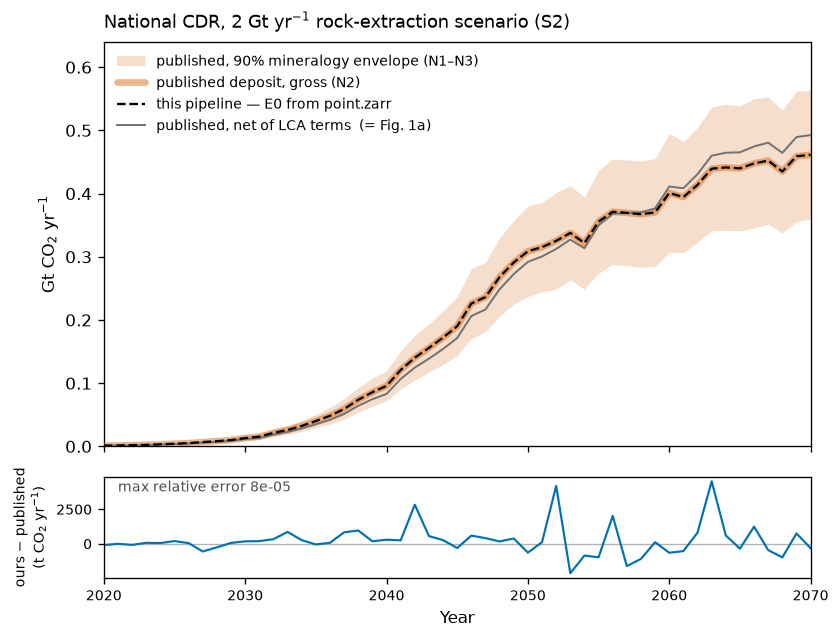

In [4]:
FL   = ["CO2", "grem", "trem", "spem", "feem_P", "feem_K"]
dbs  = {f: io.load_published(f) for f in FL}
ids  = [int(p) for p in pt.point.values]     # point IS the key of the published pickles

pub   = {N: {f: sum(dbs[f][p][f"{f}_a_b"][f"S{SCEN}_U1_N{N}_p100"].values for p in ids) / 1e9
             for f in FL} for N in (1, 2, 3)}
gross = {N: pub[N]["CO2"] for N in pub}
net   = {N: pub[N]["CO2"] - sum(pub[N][f] for f in FL[1:]) for N in pub}

ours = national("cdr_total")
d    = (ours - gross[2]) * 1e9                                  # t CO2/yr
rel  = np.abs(d) / np.where(gross[2] > 0, gross[2] * 1e9, np.nan)

print(f"annual national CDR, Gt CO2/yr        2050      2070")
print(f"  ours (E0, point.zarr)           {ours[YRS == 2050][0]:8.4f}  {ours[-1]:8.4f}")
print(f"  published deposit, gross (N2)   {gross[2][YRS == 2050][0]:8.4f}  {gross[2][-1]:8.4f}")
print(f"  published, N1-N3 envelope        {gross[1][YRS == 2050][0]:.3f}-{gross[3][YRS == 2050][0]:.3f}"
      f"    {gross[1][-1]:.3f}-{gross[3][-1]:.3f}")
print(f"  published, net of LCA terms     {net[2][YRS == 2050][0]:8.4f}  {net[2][-1]:8.4f}"
      f"   (paper: 0.16 +/- 0.04, 0.25 +/- 0.05)")
print(f"\nreproduction: max |ours - published| = {np.abs(d).max():,.0f} t CO2/yr, "
      f"max relative error {np.nanmax(rel):.1e}")
assert np.nanmax(rel) < 1e-3, "national curve does not reproduce the published deposit"

fig, axes = plt.subplots(2, 1, figsize=(7.6, 5.8), sharex=True,
                         gridspec_kw=dict(height_ratios=[4, 1], hspace=.12))

ax = axes[0]
ax.fill_between(YRS, gross[1], gross[3], color=OI["vermillion"], alpha=.20, lw=0,
                zorder=2, label="published, 90% mineralogy envelope (N1–N3)")
ax.plot(YRS, gross[2], color=OI["vermillion"], lw=4.0, alpha=.45, zorder=3,
        solid_capstyle="round", label="published deposit, gross (N2)")
ax.plot(YRS, ours, color="k", lw=1.4, ls="--", zorder=5,
        label="this pipeline — E0 from point.zarr")
ax.plot(YRS, net[2], color=OI["grey"], lw=1.2, zorder=4,
        label="published, net of LCA terms  (= Fig. 1a)")
ax.set_xlim(2020, 2070); ax.set_ylim(0, .64)
ax.set_ylabel("Gt CO$_2$ yr$^{-1}$")
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
ax.set_title(f"National CDR, {SCEN} Gt yr$^{{-1}}$ rock-extraction scenario (S{SCEN})",
             loc="left", fontsize=10.5, pad=8)

ax = axes[1]
ax.axhline(0, color="0.7", lw=.8)
ax.plot(YRS, d, color=OI["blue"], lw=1.3)
ax.set_xlabel("Year")
ax.set_ylabel("ours − published\n(t CO$_2$ yr$^{-1}$)", fontsize=8.5)
ax.tick_params(labelsize=8.5)
ax.text(2021, ax.get_ylim()[1] * .78,
        f"max relative error {np.nanmax(rel):.0e}", fontsize=8.5, color="0.3")

fig.savefig(FIGDIR / "05_fig3_national_cdr.png", bbox_inches="tight", dpi=200)
plt.show()

## 4. National CDR under E1 and E2

- **E1**: keep alkalinity release; pH and SIC formation rise.
- **E2**: keep pCO2 and pH

         2070 rate    cumulative 2020-2070
E0       0.461 Gt/yr           10.58 Gt
E1       0.413 Gt/yr            9.40 Gt   (89% of E0)
E2       0.182 Gt/yr            3.84 Gt   (36% of E0)


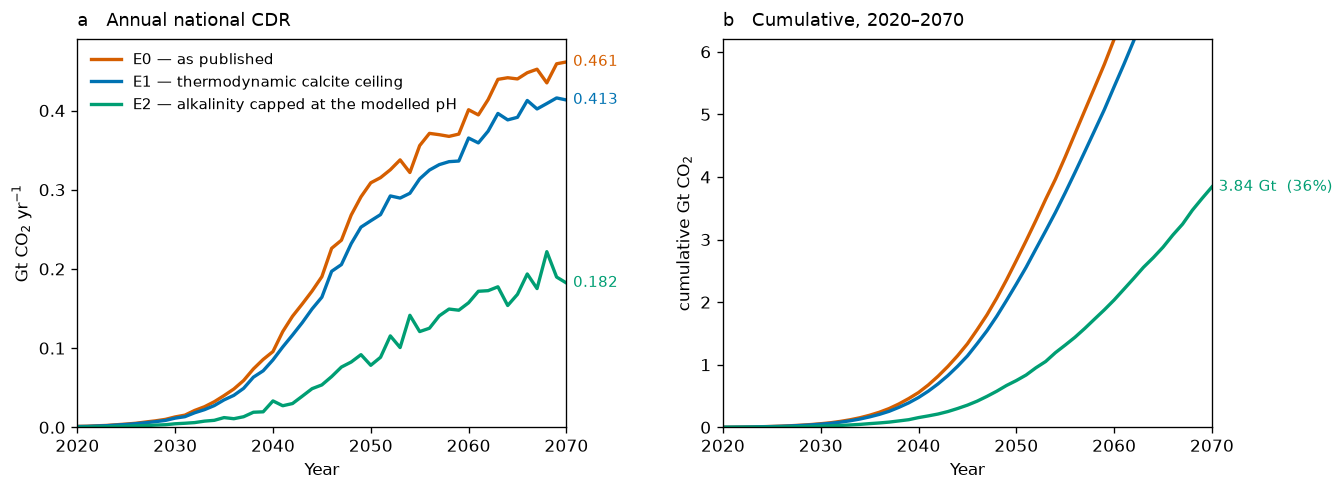

In [5]:
SER = [("E0", "cdr_total",    OI["vermillion"], "E0 — as published"),
       ("E1", "cdr_total_e1", OI["blue"],       "E1 — thermodynamic calcite ceiling"),
       ("E2", "cdr_total_e2", OI["green"],      "E2 — alkalinity capped at the modelled pH")]

rate = {k: national(v) for k, v, _, _ in SER}
cum  = {k: (pt[v].fillna(0.0).sum("point") / 1e9).values for k, v, _, _ in SER}

e0 = cum["E0"][-1]
print(f"{'':4s}  {'2070 rate':>12s}  {'cumulative 2020-2070':>22s}")
for k, _, _, _ in SER:
    share = "" if k == "E0" else f"   ({cum[k][-1] / e0:.0%} of E0)"
    print(f"{k:4s}  {rate[k][-1]:8.3f} Gt/yr  {cum[k][-1]:14.2f} Gt{share}")

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.2))
fig.subplots_adjust(wspace=.32)

ax = axes[0]
for k, _, c, lab in SER:
    ax.plot(YRS, rate[k], color=c, lw=2.0, label=lab)
    ax.annotate(f"{rate[k][-1]:.3f}", xy=(2070, rate[k][-1]), xytext=(4, 0),
                textcoords="offset points", color=c, fontsize=9, va="center")
ax.set_xlim(2020, 2070); ax.set_ylim(0, .49)
ax.set_xlabel("Year"); ax.set_ylabel("Gt CO$_2$ yr$^{-1}$")
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.set_title("a   Annual national CDR", loc="left", fontsize=10.5, pad=8)

ax = axes[1]
for k, _, c, _ in SER:
    ax.plot(YRS, cum[k], color=c, lw=2.0)
    ax.annotate(f"{cum[k][-1]:.2f} Gt" +
                ("" if k == "E0" else f"  ({cum[k][-1] / cum['E0'][-1]:.0%})"),
                xy=(2070, cum[k][-1]), xytext=(4, 0), textcoords="offset points",
                color=c, fontsize=9, va="center")
ax.set_xlim(2020, 2070); ax.set_ylim(0, 6.2)
ax.set_xlabel("Year"); ax.set_ylabel("cumulative Gt CO$_2$")
ax.set_title("b   Cumulative, 2020–2070", loc="left", fontsize=10.5, pad=8)

fig.savefig(FIGDIR / "05_fig4_e0_e1_e2.png", bbox_inches="tight", dpi=200)
plt.show()